In [15]:

!pip install -q fastapi uvicorn python-multipart pillow requests matplotlib

import torch
import torchvision
from torchvision import models
from PIL import Image, ImageDraw, ImageFont
import io
import time
import threading
import uvicorn
import requests
import matplotlib.pyplot as plt

# Check GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

model = model.to(device)
model.eval()

# Image preprocessing
preprocess = weights.transforms()

# Image classification labels
labels = weights.meta["categories"]

print("\nResNet18 Model Loaded Successfully!")
print("Execution Device:", device)


PyTorch: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4

ResNet18 Model Loaded Successfully!
Execution Device: cuda


In [16]:

def predict_image(image):

    start_time = time.time()

    # Convert image to RGB
    image = image.convert("RGB")

    # Preprocess image
    input_tensor = preprocess(image).unsqueeze(0)

    # Move image to GPU
    input_tensor = input_tensor.to(device)

    # Perform prediction
    with torch.inference_mode():

        outputs = model(input_tensor)

        probabilities = torch.nn.functional.softmax(
            outputs, dim=1
        )

    # Get highest prediction
    confidence, predicted = torch.max(
        probabilities, 1
    )

    prediction = labels[predicted.item()]

    # Get top 5 predictions
    top_prob, top_indices = torch.topk(
        probabilities, 5, dim=1
    )

    top_predictions = []

    for prob, idx in zip(
        top_prob[0].tolist(),
        top_indices[0].tolist()
    ):
        top_predictions.append({
            "label": labels[idx],
            "confidence": round(prob * 100, 2)
        })

    inference_time = (
        time.time() - start_time
    ) * 1000

    return {
        "prediction": prediction,
        "confidence": round(
            confidence.item() * 100, 2
        ),
        "inference_time_ms": round(
            inference_time, 2
        ),
        "device": str(device),
        "top_predictions": top_predictions
    }

print("Prediction Function Ready!")


Prediction Function Ready!


In [17]:

from fastapi import FastAPI, UploadFile, File, HTTPException

app = FastAPI(
    title="VisionPort AI",
    description="End-to-End Computer Vision Inference System",
    version="2.0"
)

@app.get("/")
def home():

    return {
        "message": "Welcome to VisionPort",
        "status": "Online",
        "model": "ResNet18",
        "device": str(device)
    }


@app.get("/health")
def health():

    return {
        "status": "healthy",
        "gpu_available": torch.cuda.is_available(),
        "model_loaded": True
    }


@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    try:
        image_bytes = await file.read()

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        result = predict_image(image)

        return {
            "filename": file.filename,
            "result": result
        }

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=str(e)
        )

print("VisionPort FastAPI Application Created!")


VisionPort FastAPI Application Created!


In [18]:

config = uvicorn.Config(
    app,
    host="127.0.0.1",
    port=8000,
    log_level="error"
)

api_server = uvicorn.Server(config)

server_thread = threading.Thread(
    target=api_server.run,
    daemon=True
)

server_thread.start()

time.sleep(5)

# Test server
response = requests.get(
    "http://127.0.0.1:8000/",
    timeout=15
)

print("Server Status:", response.status_code)
print("Server Response:", response.json())


ERROR:    [Errno 98] error while attempting to bind on address ('127.0.0.1', 8000): address already in use


Server Status: 200
Server Response: {'message': 'Welcome to VisionPort', 'status': 'Online', 'model': 'ResNet18', 'device': 'cuda'}


Saving traffic.jpg to traffic (2).jpg


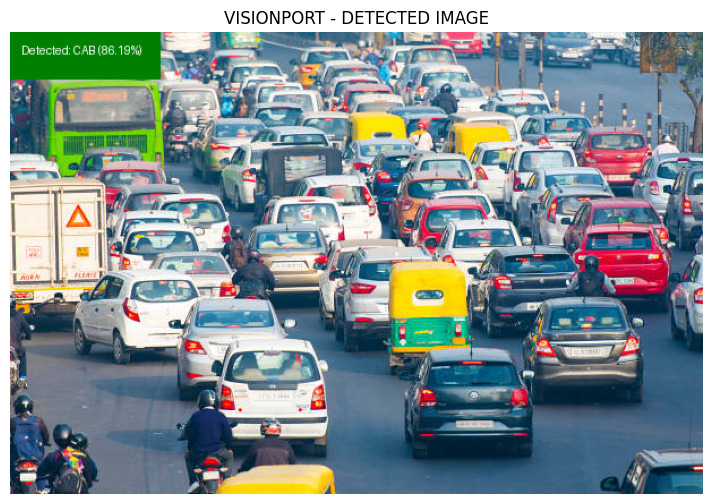


Prediction: cab
Confidence: 86.19 %
Inference Time: 15.0 ms
Device: cuda


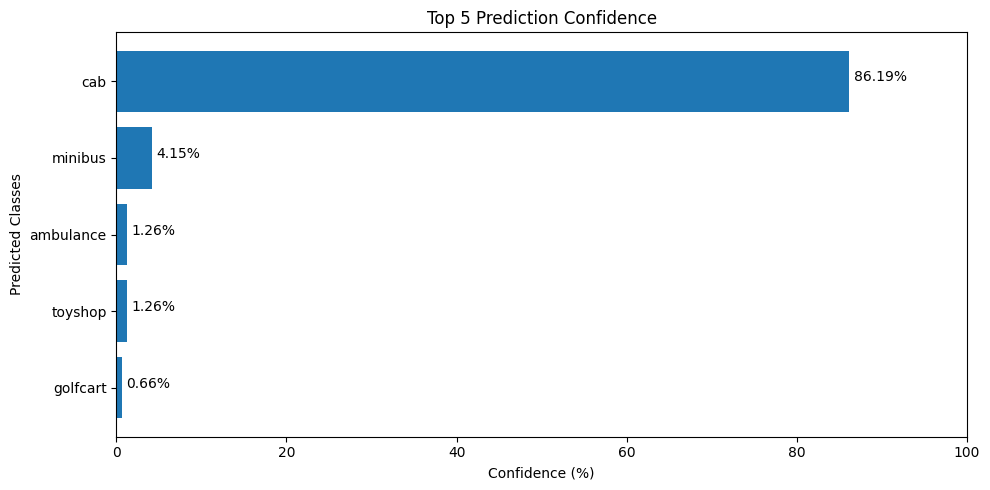

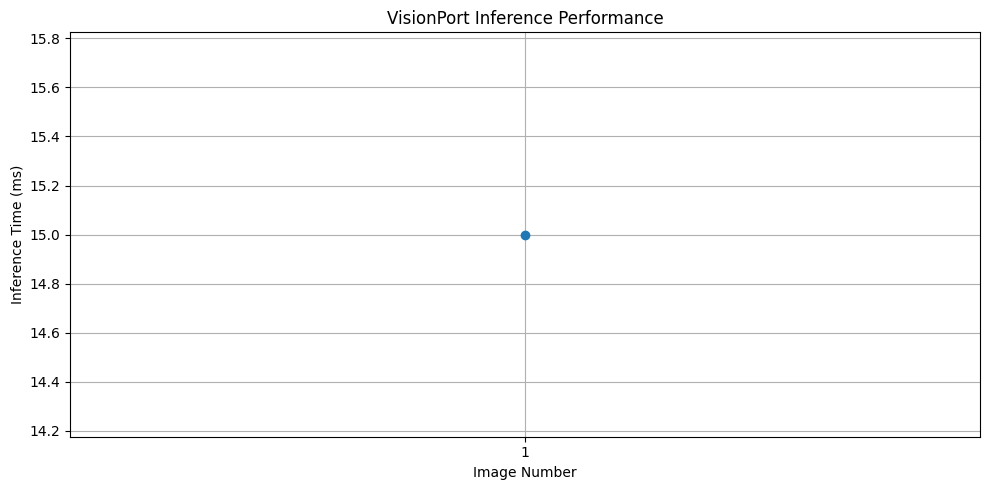

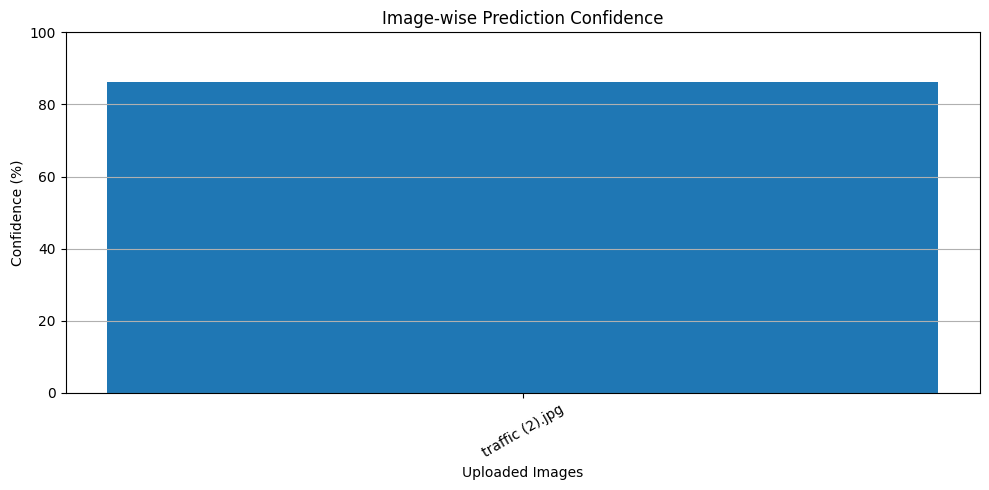


========== VISIONPORT ANALYTICS ==========
Total Images: 1
Average Inference Time: 15.0 ms
Average Confidence: 86.19 %


In [21]:

from google.colab import files
from IPython.display import display
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import io
import requests
import time

# Store performance information
inference_times = []
prediction_confidences = []
image_names = []

# Upload multiple images
uploaded = files.upload()

for filename, file_data in uploaded.items():

    # Open original image
    original_image = Image.open(
        io.BytesIO(file_data)
    ).convert("RGB")

    # Send image to FastAPI
    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={
            "file": (
                filename,
                file_data,
                "image/jpeg"
            )
        },
        timeout=60
    )

    if response.status_code != 200:
        print("Error:", response.text)
        continue

    result = response.json()["result"]

    prediction = result["prediction"]
    confidence = result["confidence"]
    inference_time = result["inference_time_ms"]

    # Store analytics
    inference_times.append(inference_time)
    prediction_confidences.append(confidence)
    image_names.append(filename)

    # Create annotated image
    output_image = original_image.copy()
    draw = ImageDraw.Draw(output_image)

    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            25
        )
    except:
        font = ImageFont.load_default()

    text = f"Detected: {prediction.upper()} ({confidence}%)"

    bbox = draw.textbbox((0, 0), text, font=font)

    draw.rectangle(
        [0, 0, min(bbox[2] + 25, output_image.width),
         bbox[3] + 30],
        fill="green"
    )

    draw.text(
        (10, 10),
        text,
        fill="white",
        font=font
    )

    # Display detected image
    plt.figure(figsize=(10, 6))
    plt.imshow(output_image)
    plt.axis("off")
    plt.title("VISIONPORT - DETECTED IMAGE")
    plt.show()

    print("\nPrediction:", prediction)
    print("Confidence:", confidence, "%")
    print("Inference Time:", inference_time, "ms")
    print("Device:", result["device"])

    # --------------------------------
    # GRAPH 1: TOP 5 CONFIDENCE
    # --------------------------------

    top_predictions = result["top_predictions"]

    names = [
        item["label"] for item in top_predictions
    ]

    scores = [
        item["confidence"] for item in top_predictions
    ]

    plt.figure(figsize=(10, 5))

    bars = plt.barh(names, scores)

    plt.xlabel("Confidence (%)")
    plt.ylabel("Predicted Classes")
    plt.title("Top 5 Prediction Confidence")

    plt.xlim(0, 100)
    plt.gca().invert_yaxis()

    for bar, score in zip(bars, scores):
        plt.text(
            score + 0.5,
            bar.get_y() + bar.get_height()/2,
            f"{score:.2f}%"
        )

    plt.tight_layout()
    plt.show()


# --------------------------------
# GRAPH 2: INFERENCE TIME
# --------------------------------

if inference_times:

    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(inference_times) + 1),
        inference_times,
        marker="o",
        linewidth=2
    )

    plt.xlabel("Image Number")
    plt.ylabel("Inference Time (ms)")
    plt.title("VisionPort Inference Performance")

    plt.xticks(
        range(1, len(inference_times) + 1)
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()


# --------------------------------
# GRAPH 3: CONFIDENCE COMPARISON
# --------------------------------

if prediction_confidences:

    plt.figure(figsize=(10, 5))

    plt.bar(
        image_names,
        prediction_confidences
    )

    plt.xlabel("Uploaded Images")
    plt.ylabel("Confidence (%)")
    plt.title("Image-wise Prediction Confidence")

    plt.ylim(0, 100)
    plt.xticks(rotation=30)

    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


# --------------------------------
# PERFORMANCE SUMMARY
# --------------------------------

if inference_times:

    print("\n========== VISIONPORT ANALYTICS ==========")

    print("Total Images:", len(inference_times))

    print(
        "Average Inference Time:",
        round(sum(inference_times) / len(inference_times), 2),
        "ms"
    )

    print(
        "Average Confidence:",
        round(
            sum(prediction_confidences) /
            len(prediction_confidences), 2
        ),
        "%"
    )

    print("==========================================")


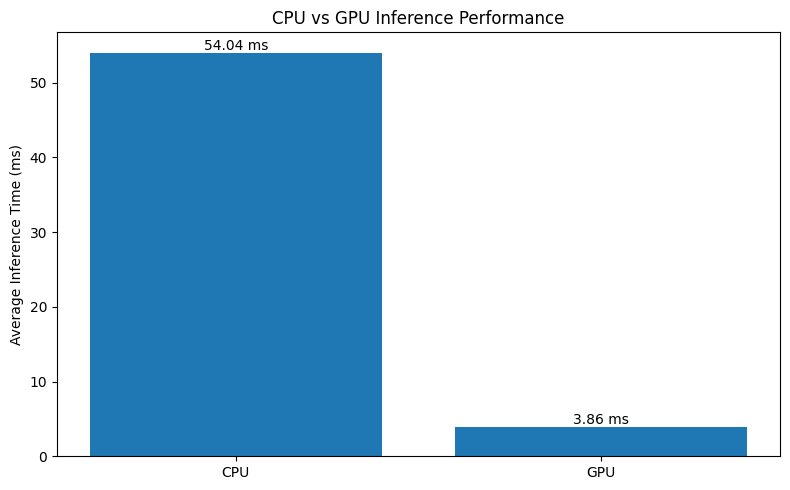

CPU Inference: 54.04 ms
GPU Inference: 3.86 ms
GPU Speedup: 14.02 times


In [22]:

import torch
import time
import matplotlib.pyplot as plt

# Create sample input
dummy_input = torch.randn(1, 3, 224, 224)

# CPU model
cpu_model = model.to("cpu")
cpu_model.eval()

cpu_input = dummy_input.to("cpu")

# Warm-up
with torch.inference_mode():
    for _ in range(5):
        cpu_model(cpu_input)

# Measure CPU
start = time.perf_counter()

with torch.inference_mode():
    for _ in range(20):
        cpu_model(cpu_input)

cpu_time = (
    (time.perf_counter() - start) / 20
) * 1000

gpu_time = None

# GPU model, if available
if torch.cuda.is_available():

    gpu_model = model.to("cuda")
    gpu_input = dummy_input.to("cuda")

    # Warm-up GPU
    with torch.inference_mode():
        for _ in range(5):
            gpu_model(gpu_input)

    torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        for _ in range(20):
            gpu_model(gpu_input)

    torch.cuda.synchronize()

    gpu_time = (
        (time.perf_counter() - start) / 20
    ) * 1000

# Plot comparison
devices = ["CPU"]
times = [cpu_time]

if gpu_time is not None:
    devices.append("GPU")
    times.append(gpu_time)

plt.figure(figsize=(8, 5))

bars = plt.bar(devices, times)

plt.ylabel("Average Inference Time (ms)")
plt.title("CPU vs GPU Inference Performance")

for bar, value in zip(bars, times):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.2f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("CPU Inference:", round(cpu_time, 2), "ms")

if gpu_time is not None:
    print("GPU Inference:", round(gpu_time, 2), "ms")

    print(
        "GPU Speedup:",
        round(cpu_time / gpu_time, 2),
        "times"
    )
